In [1]:
from aoeb.chromatic import ChromaticModel
from aoeb.config import DEFAULTS                       # these live in config/defaults.yml (cfg.chromatic() builds it)
from aoeb.psf import PsfEngine                         # separate from the budget: budget.py does not import psf.py
from aoeb.budget import ErrorBudgetMachine
from aoeb.noise import Detector
from aoeb import plotting as pl

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
import matplotlib as mpl
# from cycler import cycler

cmap = mpl.colormaps['jet'] # 1. Choose your colormap (e.g., 'hot', 'jet', 'turbo')
colors = cmap(np.linspace(0.0, 1.0, 9)) # 2. Extract a set of colors from it (e.g., 6 distinct colors across the map)
# plt.rcParams['axes.prop_cycle'] = cycler(color=colors) # 3. Apply it to the default line cycle
plt.rcParams['image.cmap'] = 'inferno' # 4. Change the default colormap for images/scatter plots
plt.rcParams.update({
    "text.usetex": True, # Use LaTeX to write all text
    "font.family": "serif", # Use a serif font
    "font.serif": ["Computer Modern Roman"] # Specifically use the classic LaTeX font
})
plt.rcParams['image.origin'] = 'lower'

In [1]:
det = Detector(ron_e=0.5, qe=0.2, excess_noise=False)       # EMCCD: readout_level 0.5, F2 = 2
m = ErrorBudgetMachine('/raid1/mmenessini/calibration/VLT/', diameter=8.2, L0=25., wind=12., 
                       detector=det, pupilstop_tag='vlt_pupil_220pixels', dm_tag='dm1200_220pix')
r = m.budget(rMod=0, n_subap=48, seeing=0.9, flux=1e7, fs=2000., latency_s=250e-6, optimize_freq=False,
             controller='leaky', scenario='standard', wavelength_nm=750., crosstalk=True)
r.totals()                       # lag, noise (+ noise_photon, noise_ron), alias, xtalk, fitting, total [nm^2], total_rms [nm]


NameError: name 'Detector' is not defined

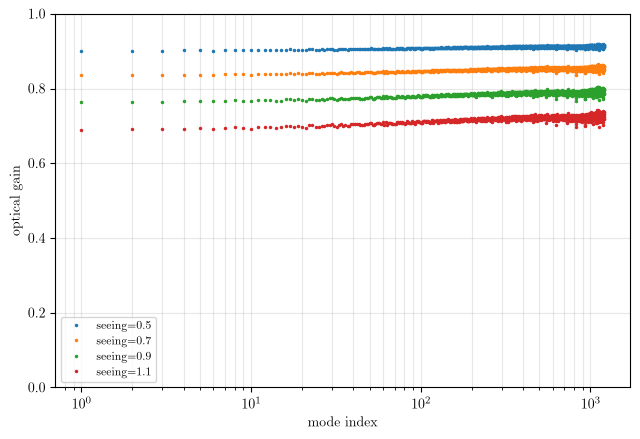

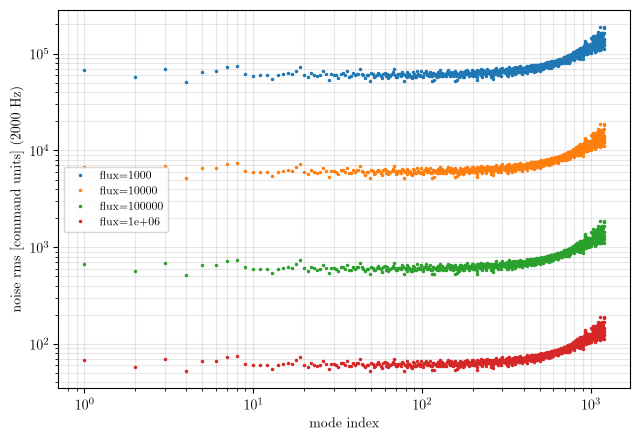

In [4]:
# Caloibration checks
fig = pl.plot_calibration(m, 'og', hue='seeing', values=[0.5, 0.7, 0.9, 1.1], rMod=0, n_subap=48, wavelength_nm=750, logx=True, ylim=[0,1])    # optical gain per mode
# fig = pl.plot_calibration(m, 'thrp', hue='rMod', values=[0, 1, 2, 3], n_subap=48, seeing=0.9, wavelength_nm=750)    # throughput versus rMod
fig = pl.plot_calibration(m, 'noise', hue='flux', values=[1e+3,1e+4,1e+5,1e+6], rMod=0, n_subap=48, fs=2000, seeing=0.9, wavelength_nm=750, logx = True)    # optical gain per mode
# fig = pl.plot_modal_variance_check(m, rMod=3, n_subap=48, seeing=0.9, wavelength_nm=750)

Cupy import successfull. Installed version is: 13.3.0


/raid1/mmenessini/git/SPECULA/config/aoeb/budget.py:377: UserWarning: 48x48, rMod 0, seeing 0.9, flux 3e+07: best at 800 Hz (max 2000) and 1200 modes (max 1200): total 81.1 nm instead of 82.6 nm
  warnings.warn(f"{n_subap}x{n_subap}, rMod {rMod}, seeing {seeing}, flux {flux:.3g}: best at {r.params['freqUsedInHz']:.0f} Hz "


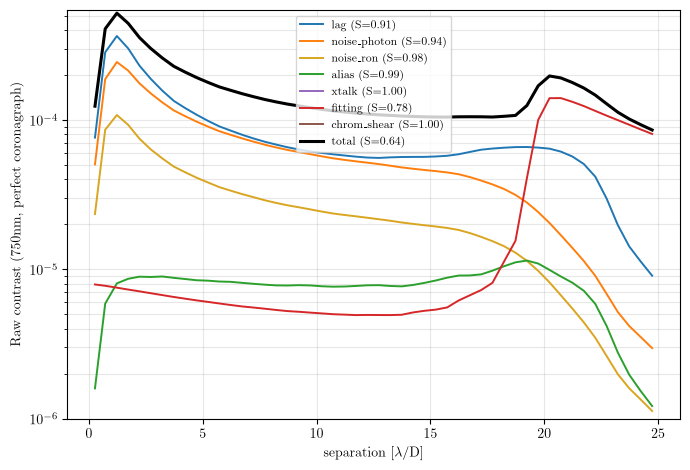

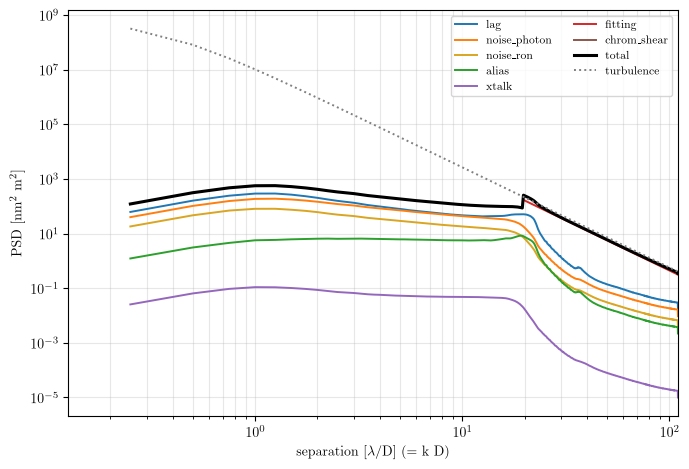

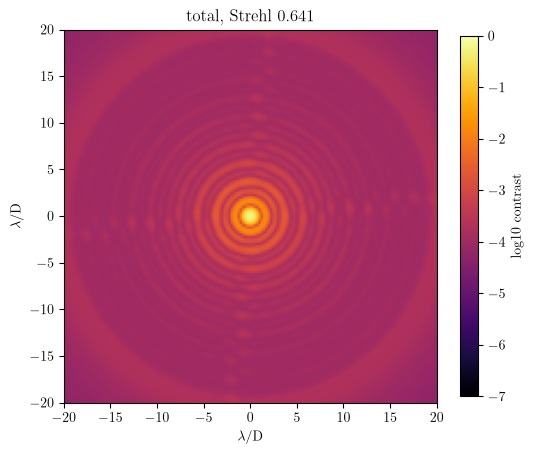

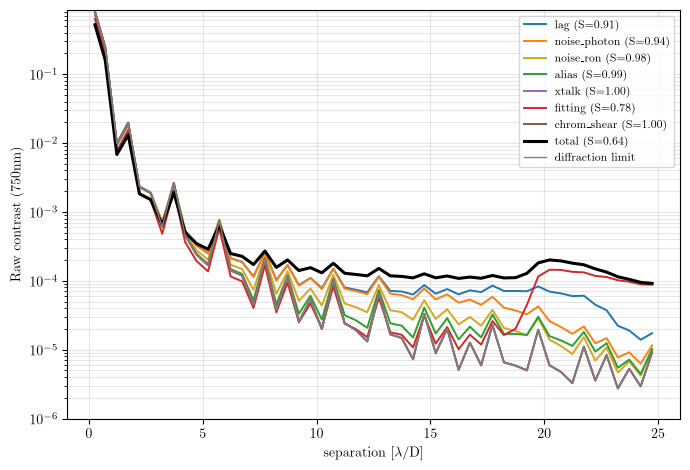

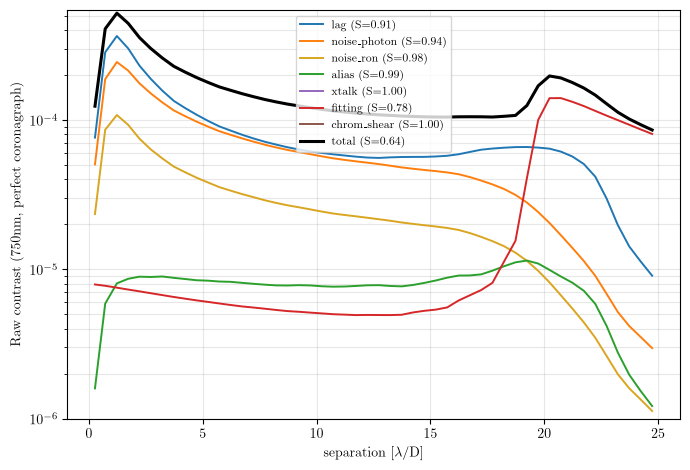

In [6]:
atm = DEFAULTS['atmosphere']
chrom = ChromaticModel(atm['heights'], atm['cn2'], science_nm=750., 
                       zenith_deg=10.,
                       multiplicative=False,                # optional, default off (A24, A26): loop-dependent, gains optimised for it
                       fresnel=False, scintillation=False)  # optional, default off
r = m.budget(rMod=0, n_subap=48, seeing=0.9, flux=3e+7, fs=2000., latency_s=250e-6, N=1200,
             controller='leaky', scenario='standard', wavelength_nm=750., crosstalk=True, chromatic=chrom)
eng = PsfEngine(m)                   # (or cfg.psf_engine()); caches the KL kernels and the telescope OTF
ps = eng.psd_terms(r)                # lag, noise_photon, noise_ron, alias, xtalk, fitting, chrom_shear, chrom_mult, total, turbulence (open loop)
res = eng.psf_terms(r, 750.)        # long-exposure PSF of every term alone and of the total, any science wavelength
res.profile('total'); res.contrast_at([2, 5, 10]); res.halo['lag']      # halos (first order) add up
pl.plot_psd_terms(ps)
pl.plot_psf_image(res)
pl.plot_psf_terms(res, rmax=25)
pl.plot_psf_terms(res, kind='coro', rmax=25)

In [ ]:
pl.plot_psf_terms(res, kind='coro', rmax=25)
print(res.contrast_at([2,3,4,5], kind='coro'))
plt.show()

In [5]:
seeings = [0.7,0.9,1.1]
rMods = [0,1,2,3]
fluxes = (10**np.arange(3,7)).tolist()
n_subaps = [48]
freqs = [500,1000,2000]
modes, totals = m.scan(seeings, rMods, n_subaps, fluxes, freqs, scenarios=('standard', 'multistage'),
                       wavelengths=[750.], store_modes=list(range(1200)))

/raid1/mmenessini/git/SPECULA/config/aoeb/budget.py:504: UserWarning: optimisation: lower frame rate in 288 and fewer modes in 0 of 288 configurations (columns freqUsedInHz, NmodesUsed)
  warnings.warn(f'optimisation: lower frame rate in {nf} and fewer modes in {nm} of {len(tot)} configurations '


In [6]:
totals = pd.read_csv('results/scan_totals.csv')              # or: modes, totals = m.scan(...)
modes = pd.read_csv('results/scan_modes.csv')
one = {'scenario': 'standard', 'controller': 'int', 'rMod': 3, 'seeing': 0.9, 'Nsubaps': 48, 'wavelength_nm': 750}

# 1. every term of ONE configuration versus flux
fig = pl.plot_budget_terms(totals, x='photPerMs', filters={**one, 'freqInHz': 1000},
                           terms=('lag', 'noise_photon', 'noise_ron', 'alias', 'fitting', 'total'))
fig.savefig('terms_vs_flux.png', dpi=150)

# 2. one quantity, a curve per frame rate, a panel per sensor
fig = pl.plot_budget_compare(totals, x='photPerMs', hue='freqInHz', quantity='total', col='Nsubaps',
                             filters={k: v for k, v in one.items() if k != 'Nsubaps'})

# 3. per-mode residual of one configuration, a curve per flux
fig = pl.plot_per_mode(modes, y='residual', hue='photPerMs', filters={**one, 'freqInHz': 1000})

FileNotFoundError: [Errno 2] No such file or directory: 'results/scan_totals.csv'